# Generators in Python
## Our smart-home story going on...

**Student notebook · Guided examples, detailed explanations, and 15 exercises**

Our temperature-monitoring project has grown. At first, a sensor gave us three readings, so putting them in a list was an excellent solution. Now the client wants a dashboard (we will implement it in the future - for now we focus on preparing the data) that can start working before a whole day's measurements have arrived. It should also process old log files without loading every line at once. Later, it will perform also statistical analysis.

We will build towards these requirements gradually. The first examples fit on a few lines. We will examine what they do, predict their output, and only then introduce a new idea. The aim is not to hide a finished system behind helper functions. It is to understand how a few ordinary Python functions can cooperate to process a stream.

**The central question:** what changes when a function offers its next result only when another part of our program asks for it?

### Before you begin

The exercise placeholders raise `NotImplementedError`. The small checking helper below reports unfinished exercises as **TODO** rather than stopping the notebook. Replace a placeholder and rerun its check. Incorrect completed answers are not silently ignored.

### A route through the notebook

| Route | Story | Main ideas |
|:--|:--|:--|
| [1–5: foundations](#s01) | A dashboard asks for its next reading. | Iterable, iterator, `iter`, `next`, `yield`, exhaustion, `return`, expressions. |
| [6–9: a growing stream](#s06) | A simulated sensor runs on demand. | Bounded consumption, pipelines, running state, rolling windows. |
| [10–13: practical tools](#s10) | Measurements arrive in batches and files. | `itertools`, `yield from`, parsing, delayed errors, cleanup, memory. |
| [14: capstone](#s14) | A dashboard reports sustained warmth. | A small streaming monitor with an explicit data contract. |
| [15: optional extension](#s15) | A consumer sends an adjustment back. | `send`, generator return values, and delegation. |
| [16: review](#s16) | Choose an appropriate design. | Decision guide, common mistakes, glossary, and references. |


In [2]:
import sys
from math import isclose, isfinite
from types import GeneratorType

print("Python:", sys.version.split()[0])

Python: 3.13.16


### The exercise checks are ordinary Python

The helper only catches the special placeholder exception. A real mistake, such as returning the wrong result or dividing by zero, remains an error. Some exercises also check **when** the input is consumed; getting the final numbers right is only part of writing a streaming function.

In [5]:
exercise_status = {}


def run_check(label, check):
    """Report unfinished work; let genuine mistakes remain visible."""
    exercise_status[label] = "running"
    try:
        check()
    except NotImplementedError:
        exercise_status[label] = "TODO"
        print(f"{label}: TODO — replace the placeholder, then rerun this check.")
    except Exception:
        exercise_status[label] = "failed"
        raise
    else:
        exercise_status[label] = "passed"
        print(f"{label}: all supplied checks passed.")


def assert_raises(exception_type, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except exception_type:
        return
    raise AssertionError(f"Expected {exception_type.__name__}")

<a id="s01"></a>

# 1. A useful list, followed by a new requirement

> **New requirement:** “Show the first corrected measurement now. Do not wait until every
> measurement has been processed.”

A list is a collection that already holds its elements. With three readings, it is easy
to inspect, reuse, and pass around. There is no need to replace a good list merely because
we have learned a new Python feature.

Our first function corrects a small calibration offset. The `print` statements are
teaching instruments: they show when each calculation occurs. They would normally be
removed from a reusable calculation.

In [ ]:
def calibrated_list(values_c, offset_c):
    corrected = []
    for value_c in values_c:
        print("Calculating:", value_c)
        corrected.append(value_c + offset_c)
    return corrected


readings_c = [20.0, 20.5, 21.0]
result = calibrated_list(readings_c, offset_c=0.3)
print("The dashboard can now use:", result[0])

Calculating: 20.0
Calculating: 20.5
Calculating: 21.0
The dashboard can now use: 20.3


The dashboard gets its first value only after the function has filled the whole output
list. This is **eager evaluation**: do the requested collection of work now, before
returning the collection.

A different arrangement would let the dashboard ask for one value, display it, and only
then ask for another. We call that **lazy evaluation** when work is postponed until its
result is requested. “Lazy” describes the timing of the work, not poor-quality code.

For this example, the useful distinction is not three values versus three million. It is
whether the caller must receive the entire result collection before it can use any of it.
An input might also be a device or file, rather than a list whose values already exist
in memory.

Before changing our function, we need to understand the question that a Python `for` loop
already knows how to ask: **“What is your next item?”**

**Discuss:** suppose the dashboard closes after the first reading. Which calculations
in the example above have already happened? Which could potentially have been avoided?

<a id="s02"></a>

# 2. Iterable, iterator, and the next item

> **New requirement:** “Let us advance through readings ourselves, one request at a time.”

An **iterable** is an object that can supply an iterator. An **iterator** is an object
that keeps the position of one traversal and supplies its next item. `iter(source)` asks
for an iterator; `next(iterator)` asks it to advance. When it has finished, it signals
`StopIteration`. A `for` loop handles that normal ending for us.

A list is iterable, but is not itself an iterator. Calling `iter` on it creates a
separate traversal position. Think of the list as the measurements written on a page,
and the iterator as a bookmark used while reading that page. This is an analogy about
position, not a promise that every iterable stores a complete page of data.

Reference: [Python tutorial — iterators](https://docs.python.org/3.13/tutorial/classes.html#iterators).

In [ ]:
measurements = [20.0, 20.5, 21.0]
bookmark = iter(measurements)

print("First request:", next(bookmark))
print("Second request:", next(bookmark))
print("Remaining values:", list(bookmark))
print("After exhaustion:", next(bookmark, "END"))
print("The original list:", measurements)

First request: 20.0
Second request: 20.5
Remaining values: [21.0]
After exhaustion: END
The original list: [20.0, 20.5, 21.0]


`list(bookmark)` is not a harmless preview: it requests **all remaining items** and stores
them in a new list. Afterwards, the bookmark is at the end. The original measurements
are still present; consuming a list iterator did not delete elements from that list.

The optional second argument in `next(bookmark, "END")` is a default to return when no
item remains. We use a string here because the actual measurements are numbers. Without
that default, an exhausted iterator raises `StopIteration`.

Let us compare two independent bookmarks with two names for the same bookmark.

In [ ]:
left = iter(measurements)
right = iter(measurements)
print("Independent positions:", next(left), next(right))

alias = left
print("Another name, same iterator:", alias is left)
print("Advance through alias:", next(alias))
print("Continue through left:", next(left))
print("An iterator returns itself from iter:", iter(left) is left)

Independent positions: 20.0 20.0
Another name, same iterator: True
Advance through alias: 20.5
Continue through left: 21.0
An iterator returns itself from iter: True


`alias = left` did not copy or rewind anything. Both names refer to one iterator, so they
share its position. This will matter when a logger and a dashboard try to use the same
stream.

A `for` loop can be understood using the following small manual version. The `try` block
contains only the request for the next item. That way, `StopIteration` raised by the loop
body would not accidentally be mistaken for normal input exhaustion.

In [ ]:
iterator = iter([20.0, 20.5])
while True:
    try:
        value_c = next(iterator)
    except StopIteration:
        break
    print("Display:", value_c)

Display: 20.0
Display: 20.5


<a id="e01"></a>

## Ex1: Take a preview and then consume the rest

Write `preview_and_rest(values)` for a **finite iterable of numbers**. Return a tuple
containing the first value, the second value, and a list of everything remaining.
Use `None` for either missing preview value. For example, `[20, 21, 22, 23]` should
produce `(20, 21, [22, 23])`.

Use `iter` and `next`, not indexing, slicing, or `len`. The function should also accept
an iterator, which has no promise of supporting those list operations. This preview
**does consume** the input traversal; it is not a non-destructive peek.

**Hint.** Make one iterator, ask it twice using a default, then convert only its remainder to a list.

In [ ]:
def preview_and_rest(values):
    # TODO: return (first, second, remaining_list).
    raise NotImplementedError

In [ ]:
def check_ex1():
    values = [20, 21, 22, 23]
    assert preview_and_rest(values) == (20, 21, [22, 23])
    assert values == [20, 21, 22, 23]
    assert preview_and_rest([]) == (None, None, [])
    assert preview_and_rest([20]) == (20, None, [])
    source = iter([20, 21, 22])
    assert preview_and_rest(source) == (20, 21, [22])
    assert next(source, "END") == "END"


run_check("Ex1", check_ex1)

Ex1: TODO — replace the placeholder, then rerun this check.


<a id="s03"></a>

# 3. `yield`: pause with a result, then resume

> **New requirement:** “Keep our readable function, but let it produce one corrected value
> per request.”

A **generator function** is a function whose own body contains `yield`. Calling it
creates a **generator object**, a particular kind of iterator. Its body does not start
running merely because we called the function. A request such as `next` starts it, or
resumes it after its previous `yield`.

`yield value` offers a value to the caller and suspends execution. The generator retains
the local state needed to continue afterwards. In our example, that includes its loop
position and current measurement. Each call to the generator function creates a new,
independent generator object.

Reference: [Python tutorial — generators](https://docs.python.org/3.13/tutorial/classes.html#generators).

In [ ]:
def calibrated_stream(values_c, offset_c):
    print("Body starts")
    for value_c in values_c:
        print("Before yield:", value_c)
        yield value_c + offset_c
        print("Resumed after yield:", value_c)
    print("Body finishes")


print("A. Call the function")
stream = calibrated_stream([20.0, 20.5], offset_c=0.3)
print("B. The object exists; its body has not started")
print("C. First result:", next(stream))
print("D. The caller can do something else here")
print("E. Second result:", next(stream))
print("F. Final request:", next(stream, "END"))

A. Call the function
B. The object exists; its body has not started
Body starts
Before yield: 20.0
C. First result: 20.3
D. The caller can do something else here
Resumed after yield: 20.0
Before yield: 20.5
E. Second result: 20.8
Resumed after yield: 20.5
Body finishes
F. Final request: END


### Check it step-by-step

At A, Python creates a generator object. “Body starts” appears only when the first `next` asks for a result. That request runs the function until the first `yield` (what value it will receive?). The statement after that `yield` has not run yet.

The second request resumes **after** the previous `yield`. The function prints its resumption message, advances the loop, and reaches the next `yield`. Only a further request lets it resume after that second value, finish the loop, and report exhaustion.

```text
caller:     next(stream)             work in caller           next(stream)
                 |                                                |
generator:  run → yield a value      [suspended here]          resume → yield ...
                 |                                                |
caller:     receive the value                              receive the next value
```

This is ordinary, sequential execution. While the caller is working, our suspended generator is not secretly taking measurements. A generator does not create a thread or start a scheduled taask. We will return to that distinction when we properly simulate a sensor.

### `return` and `yield` do different jobs

An ordinary function typically computes a result and finishes with `return`. A generator can offer several results through separate `yield` operations before it finishes. It can also use `return` to finish, but that does not add another ordinary item to the stream.

Do not think of a generator as a list that Python secretly fills in advance. Its body is a paused computation. It may contain a loop, decisions, local variables, and ordinary function calls. It may also retain references to existing input objects; lazy output is not a copy of the input.


In [ ]:
first_stream = calibrated_stream([20.0, 20.5], 0.3)
second_stream = calibrated_stream([20.0, 20.5], 0.3)
print("First stream:", next(first_stream))
print("Second stream:", next(second_stream))
# These examples have no external resources; close simply ends the paused computations.
first_stream.close()
second_stream.close()

Body starts
Before yield: 20.0
First stream: 20.3
Body starts
Before yield: 20.0
Second stream: 20.3


<a id="e02"></a>

## Ex2: Convert Fahrenheit readings on demand

Write `fahrenheit_stream(values_f)` as a generator function. For each finite numerical Fahrenheit reading, yield its Celsius equivalent using `(value_f - 32) * 5 / 9`.
Do not build an output list, print, or consume any input before a result is requested. The input can be a list or a one-pass iterator; an empty input yields nothing.

**Hint.** Use an ordinary `for` loop, but put `yield` where an eager version would append to a list.

In [ ]:
def fahrenheit_stream(values_f):
    # TODO: yield each converted value.
    raise NotImplementedError

In [ ]:
def check_ex2():
    converted = list(fahrenheit_stream([32, 68, 212]))
    assert len(converted) == 3
    assert all(isclose(a, b) for a, b in zip(converted, [0, 20, 100]))
    assert list(fahrenheit_stream([])) == []
    seen = []

    def source():
        for value in [32, 68, 212]:
            seen.append(value)
            yield value

    stream = fahrenheit_stream(source())
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert isclose(next(stream), 0.0)
    assert seen == [32]
    assert isclose(next(stream), 20.0)
    assert seen == [32, 68]
    stream.close()


run_check("Ex2", check_ex2)

Ex2: TODO — replace the placeholder, then rerun this check.


<a id="s04"></a>

# 4. Finishing, exhaustion, and stopping

> **New requirement:** “A disconnected sensor sends `None`. Stop that session.”

A finite generator eventually reaches the end of its body or executes `return`.
Subsequent requests find it exhausted. Calling `iter` on that generator does not rewind it; create a new generator object for a new traversal, using a source that can itself be replayed.

A pause and an ending are different states. After `yield`, execution can resume. After ordinary completion, the same generator cannot restart. This difference is particularly important in notebooks, where rerunning only a consumer cell may reuse an exhausted object.

In [ ]:
def session_values(values):
    for value in values:
        if value is None:
            return
        yield value


source = iter([20.0, 20.5, None, 99.0])
session = session_values(source)
print("Session:", list(session))
print("The same session again:", list(session))
print("Source after the marker:", next(source))

Session: [20.0, 20.5]
The same session again: []
Source after the marker: 99.0


Here `None` means “the session ended”, not “a bad temperature to skip”. This marker is consumed so that we can recognise it, but the later 99.0 is not consumed by this session.
Whether to stop, skip, or report an error is a **data-contract decision**, not a property that Python can guess for us.

To end a generator normally, use `return` or let its body finish. Do not explicitly raise `StopIteration` inside it. In modern Python, an unhandled `StopIteration` escaping a generator body becomes a `RuntimeError`; this also catches accidental exhaustion from a `next` call inside that bodys.

Reference: [PEP 479 — StopIteration inside generators](https://peps.python.org/pep-0479/).

In [ ]:
def broken_ending():
    yield 20.0
    raise StopIteration("This is not the correct way to finish")


broken = broken_ending()
print("First value:", next(broken))
try:
    next(broken)
except RuntimeError as error:
    print("Expected demonstration error:", type(error).__name__, str(error))

First value: 20.0
Expected demonstration error: RuntimeError generator raised StopIteration


### A fresh generator still needs a usable source

Two calls to `session_values([20, 21])` can each traverse that list. Two calls receiving
the **same exhausted source iterator** do not magically recover its old measurements.
For a replay, keep a small list intentionally, reopen a file, or call a source factory
that can produce a new traversal. Re-running a hardware acquisition would usually give
new measurements rather than reproduce old ones.

**Predict:** in the next exercise, should a value after the first `None` remain available
from the original source iterator? The answer is part of the contract, and the checks
will verify it.

<a id="e03"></a>

## Ex3: Stop a session without reading past it

Write `before_disconnect(values)`. Its input contains numbers and may contain `None`.
Yield every number before the first `None`, then finish. Do not yield the marker, and
do not request a later input item. With no marker, yield the whole finite input.
Use normal generator termination, not an explicit `raise StopIteration`.

**Hint.** Test for the marker before the `yield`. A `return` ends this generator immediately.

In [ ]:
def before_disconnect(values):
    # TODO: yield numbers until the first None.
    raise NotImplementedError

In [ ]:
def check_ex3():
    assert list(before_disconnect([20, 21, None, 99])) == [20, 21]
    assert list(before_disconnect([None, 20])) == []
    assert list(before_disconnect([])) == []
    assert list(before_disconnect([20, 21])) == [20, 21]
    source = iter([20, None, 99])
    stream = before_disconnect(source)
    assert isinstance(stream, GeneratorType)
    assert list(stream) == [20]
    assert next(source) == 99
    assert next(stream, "END") == "END"


run_check("Ex3", check_ex3)

Ex3: TODO — replace the placeholder, then rerun this check.


<a id="s05"></a>

# 5. Generator expressions: a shorter spelling

> **New requirement:** “Select warm readings without writing a named function.”

A **generator expression** is a compact way to create a generator object. Compare the
square brackets of a list comprehension with the parentheses of a generator expression.
They can describe the same sequence of values while doing the work at different times.

The expression producing each value and its filtering conditions are evaluated as the
expression is consumed. There is an important boundary: the leftmost iterable expression
is evaluated, and its iterator obtained, when the generator expression is created.
“Lazy” therefore does not mean that every part of its syntax is postponed.

Reference: [generator-expression evaluation](https://docs.python.org/3.13/reference/expressions.html#generator-expressions).

In [ ]:
values_c = [20.0, 22.0, 24.0]
list_result = [value + 0.3 for value in values_c if value >= 22.0]
generator_result = (value + 0.3 for value in values_c if value >= 22.0)

print("List ready now:", list_result)
print("Generator type:", type(generator_result).__name__)
print("First generated value:", next(generator_result))
print("Remaining generated values:", list(generator_result))
print("Already consumed:", list(generator_result))

List ready now: [22.3, 24.3]
Generator type: generator
First generated value: 22.3
Remaining generated values: [24.3]
Already consumed: []


We can pass a generator expression directly to a consumer. `sum` needs to visit all
items to compute its total. `any` can stop once it has found a true condition, and `all`
can stop once it has found a false condition. A consumer therefore helps determine how
much upstream work occurs.

In `sum(value for value in values_c)`, Python allows us to omit an extra pair of
parentheses because the generator expression is the only argument. This is still a
generator expression; `sum` does not turn it into a list first.

A practical caution: a generator expression is not a snapshot of every name or object
it mentions. The following example deliberately changes a calibration setting before
consumption. A function argument can give us a clearer configuration boundary.

References: [built-in consumers](https://docs.python.org/3.13/library/functions.html#any)
and [PEP 289 — binding in generator expressions](https://peps.python.org/pep-0289/).

In [ ]:
offset_c = 0.3
late_read = (value + offset_c for value in [20.0, 21.0])
offset_c = 1.0
print("Uses the offset when consumed:", list(late_read))


def with_offset(values, offset):
    return (value + offset for value in values)


configured = with_offset([20.0, 21.0], offset_c)
offset_c = 5.0
print("Keeps its numerical argument:", list(configured))

Uses the offset when consumed: [21.0, 22.0]
Keeps its numerical argument: [21.0, 22.0]


In the second case, `offset` is a local parameter holding the numerical value supplied
at the call. Rebinding the unrelated outer name `offset_c` does not change that local
binding. This is not a general deep copy: passing a mutable object and changing its
contents later can still affect deferred work.

Choose a named generator function when the logic needs several steps, explanations,
validation, or branches. Choose an expression for a short transformation whose meaning
is immediately clear. There is no prize for fitting a whole monitoring system on one line.

<a id="e04"></a>

## Ex4: Select warm values with an expression

Write `warm_values(values_c, threshold_c)` to **return a generator expression** that selects readings at or above the threshold. Preserve their order and numerical values. Assume finite numerical inputs. Do not construct a list. An empty input or no matches produces an empty stream.

**Hint.** Start from `(value for value in values_c if ...)` and return that object.

In [ ]:
def warm_values(values_c, threshold_c):
    # TODO: return a generator expression.
    raise NotImplementedError

In [ ]:
def check_ex4():
    assert list(warm_values([20, 23, 22, 25], 23)) == [23, 25]
    assert list(warm_values([], 23)) == []
    assert list(warm_values([20, 21], 23)) == []
    seen = []

    def source():
        for value in [20, 23, 25]:
            seen.append(value)
            yield value

    stream = warm_values(source(), 23)
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == 23
    assert seen == [20, 23]
    assert list(stream) == [25]
    assert list(stream) == []


run_check("Ex4", check_ex4)

Ex4: TODO — replace the placeholder, then rerun this check.


<a id="s06"></a>

# 6. A sensor that can keep producing readings

> **New requirement:** “Test the dashboard without owning a physical sensor.”

A generator does not need a predetermined number of outputs. The next example describes an unbounded sequence: it can keep producing sample records until the caller stops requesting them. We use a simple deterministic trend, a smooth oscillation, and small pseudorandom variations to make a recognisable teaching signal.

This is just a **simulation**, not a calibrated model of a real room. The `time_s` field is a simulated timestamp. Producing 60 samples does not mean that 60 seconds of wall-clock time have passed - this would need some doing, but of course it is good enough for us as an example. The generator performs no work while suspended, and it does not collect data independently of the consumer.

Our small data contract is explicit: each output is a new dictionary containing an integer `sample`, a simulated `time_s`, and a Celsius `temp_c`. The sample index starts at zero. We use a local random-number generator so this demonstration does not change an unrelated global random sequence.

In [1]:
from itertools import islice
from math import sin
from random import Random


def simulated_sensor(seed=7):
    random = Random(seed)
    sample = 0
    while True:
        temperature = 20.0 + 0.04 * sample + 0.7 * sin(sample / 5)
        temperature += random.uniform(-0.15, 0.15)
        yield {
            "sample": sample,
            "time_s": float(sample),
            "temp_c": round(temperature, 2),
        }
        sample += 1


sensor = simulated_sensor()
for record in islice(sensor, 5):
    print(record)
print("The source still has a next sample:", next(sensor))
sensor.close()

{'sample': 0, 'time_s': 0.0, 'temp_c': 19.95}
{'sample': 1, 'time_s': 1.0, 'temp_c': 20.07}
{'sample': 2, 'time_s': 2.0, 'temp_c': 20.4}
{'sample': 3, 'time_s': 3.0, 'temp_c': 20.39}
{'sample': 4, 'time_s': 4.0, 'temp_c': 20.67}
The source still has a next sample: {'sample': 5, 'time_s': 5.0, 'temp_c': 20.75}


`islice(sensor, 5)` supplies at most the first five available items from the current
position. It does not rewind or duplicate the source. After those five requests, the
underlying sensor is paused before its next sample; the direct `next(sensor)` continues
that same sequence.

Never call `list(simulated_sensor())`, `sum(...)`, or `sorted(...)` on this unbounded
source. Those consumers would wait for an end that our source does not provide. A finite
view such as `list(islice(simulated_sensor(), 5))` is safe here because this particular
source produces each requested value promptly.

The distinction matters: limiting the number of requests is not a general timeout.
A real hardware read could block, and a filter could search forever without finding a
match. Neither problem is solved merely by adding an output limit.

A generator can yield mutable objects, but it does not automatically copy them. Our
sensor creates a new dictionary on each iteration. Repeatedly updating and yielding
one shared dictionary would make stored “old” records change when that same object was
updated again. We will test record independence in the exercise.

<a id="e05"></a>

## Ex5: Build an adjustable ramp source

Write `ramp_sensor(start_c=20.0, step_c=0.5)` as an unbounded generator. Sample number `i` should be a **new dictionary** with exactly `{"sample": i, "temp_c": start_c + i * step_c}`.
Start at sample zero. Assume finite numerical settings; zero and negative steps are allowed. Do not use sleeping, printing, hardware, or an ever-growing history list.

Demonstrate it by taking a finite number of records with `islice`. Never turn the complete unbounded source into a list.

**Hint.** Keep a sample counter, yield one fresh dictionary, then increment the counter after resuming.

In [3]:
def ramp_sensor(start_c=20.0, step_c=0.5):
    # TODO: yield a new record for each sample number.
    raise NotImplementedError

In [6]:
def check_ex5():
    from itertools import islice

    source = ramp_sensor(20.0, 0.5)
    assert isinstance(source, GeneratorType)
    records = list(islice(source, 3))
    assert records == [
        {"sample": 0, "temp_c": 20.0},
        {"sample": 1, "temp_c": 20.5},
        {"sample": 2, "temp_c": 21.0},
    ]
    assert len({id(record) for record in records}) == 3
    assert next(source) == {"sample": 3, "temp_c": 21.5}
    source.close()
    cooling = ramp_sensor(10.0, -1.0)
    assert [r["temp_c"] for r in islice(cooling, 3)] == [10.0, 9.0, 8.0]
    cooling.close()
    constant = ramp_sensor(10.0, 0.0)
    assert [r["temp_c"] for r in islice(constant, 2)] == [10.0, 10.0]
    constant.close()


run_check("Ex5", check_ex5)

Ex5: TODO — replace the placeholder, then rerun this check.


<a id="s07"></a>

# 7. Connect small stages into a lazy pipeline

> **New requirement:** “Apply a calibration and show only readings at or above the alert
> threshold. Keep the original measurements unchanged.”

A **pipeline** connects a source, one or more processing stages, and a consumer. Each
stage can accept an iterable and offer an iterator of results. We do not need a special
framework: a generator object can simply be the input to another generator function.

The following stages are intentionally short. One corrects a record and creates a new
dictionary. The other decides whether the record passes a threshold. Neither stage owns
an output list. The printing remains in the consumer, where displaying a result belongs.

In [7]:
def add_calibration(records, offset_c):
    for record in records:
        yield {**record, "temp_c": record["temp_c"] + offset_c}


def select_hot(records, threshold_c):
    for record in records:
        if record["temp_c"] >= threshold_c:
            yield record


raw = [
    {"sample": 0, "temp_c": 20.0},
    {"sample": 1, "temp_c": 21.5},
    {"sample": 2, "temp_c": 23.0},
]
corrected = add_calibration(raw, offset_c=0.5)
alerts = select_hot(corrected, threshold_c=22.0)
for alert in alerts:
    print("Display:", alert)
print("Original records:", raw)

Display: {'sample': 1, 'temp_c': 22.0}
Display: {'sample': 2, 'temp_c': 23.5}
Original records: [{'sample': 0, 'temp_c': 20.0}, {'sample': 1, 'temp_c': 21.5}, {'sample': 2, 'temp_c': 23.0}]


`{**record, "temp_c": corrected_value}` creates a new dictionary containing the original
fields, with `temp_c` replaced. This is a shallow copy. Our current fields are numbers;
if a record also held a nested mutable object, that nested object would still be shared
unless we deliberately copied it too.

### Requests travel backwards; results travel forwards

```text
request:   dashboard → select_hot → add_calibration → source
result:    source → corrected record → accepted record → dashboard
```

One request from the dashboard might make the filter examine several records. It keeps
asking upstream until it finds a match or the upstream source finishes. This is a
**pull-based** arrangement: the consumer initiates the requests. It is not automatic
parallel execution of three independent workers.

Trace a first alert below. Predict how many source readings will be needed.

In [8]:
def traced_source():
    for sample, value_c in enumerate([20.0, 21.5, 23.0]):
        print("Source supplies sample", sample)
        yield {"sample": sample, "temp_c": value_c}


source = traced_source()
corrected = add_calibration(source, 0.5)
alerts = select_hot(corrected, 22.0)
print("Pipeline constructed")
print("First alert:", next(alerts))
# We own all three generator objects in this trace and end them explicitly.
alerts.close()
corrected.close()
source.close()

Pipeline constructed
Source supplies sample 0
Source supplies sample 1
First alert: {'sample': 1, 'temp_c': 22.0}


### Put the limit where the requirement belongs

“Inspect at most five input measurements” and “find five matching alerts” are different
requirements. In the next example the first arrangement limits the search to five input
records. The second asks for five output alerts and happens to need ten input records
for this finite dataset. On an unbounded source with no matching readings, the second
arrangement could search without end.

Filters can also make `any` or `next` take a long time. Short-circuiting helps only once
a decisive result is actually found. For hardware, add an appropriate acquisition
timeout at the hardware boundary; a sample-count limit is not a wall-clock timeout.

In [9]:
finite_records = [{"sample": i, "temp_c": 20.0 + i} for i in range(10)]
input_limited = select_hot(islice(iter(finite_records), 5), 25.0)
output_limited = islice(select_hot(iter(finite_records), 25.0), 5)
print("Inspect five inputs:", list(input_limited))
print("Find five alerts:", list(output_limited))

Inspect five inputs: []
Find five alerts: [{'sample': 5, 'temp_c': 25.0}, {'sample': 6, 'temp_c': 26.0}, {'sample': 7, 'temp_c': 27.0}, {'sample': 8, 'temp_c': 28.0}, {'sample': 9, 'temp_c': 29.0}]


<a id="e06"></a>

## Ex6: Calibrate first, then decide whether to alert

Write `calibrated_alerts(records, offset_c, threshold_c)`. Each input record has exactly `sample` and `temp_c`, with finite numerical temperatures. Yield a **new dictionary** for each record whose **corrected** temperature is at or above the threshold. Preserve the sample number and use the corrected temperature in the output. Do not modify inputs or build an output list.

The function must stay lazy: creating it consumess no source records, and obtaining its first alert must not consume records beyond that first match.

**Hint.** For each record, calculate the corrected value, test that value, and only then yield a new record.

In [10]:
def calibrated_alerts(records, offset_c, threshold_c):
    # TODO: yield corrected records meeting the threshold.
    raise NotImplementedError

In [11]:
def check_ex6():
    records = [
        {"sample": 0, "temp_c": 20.0},
        {"sample": 1, "temp_c": 21.5},
        {"sample": 2, "temp_c": 23.0},
    ]
    before = [record.copy() for record in records]
    result = list(calibrated_alerts(records, 0.5, 22.0))
    assert result == [
        {"sample": 1, "temp_c": 22.0},
        {"sample": 2, "temp_c": 23.5},
    ]
    assert records == before
    assert result[0] is not records[1]
    assert list(calibrated_alerts([], 0.5, 22.0)) == []
    seen = []

    def source():
        for record in records:
            seen.append(record["sample"])
            yield record

    stream = calibrated_alerts(source(), 0.5, 22.0)
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == {"sample": 1, "temp_c": 22.0}
    assert seen == [0, 1]
    stream.close()


run_check("Ex6", check_ex6)

Ex6: TODO — replace the placeholder, then rerun this check.


<a id="s08"></a>

# 8. Keep a little state: running calculations

> **New requirement:** “Show a summary after each new measurement, not only at the end.”

A generator can remember a state between its outputs. That is one of its main strengths. A **running total** means the sum of everything seen so far. For
20, 22, 24, the successive totals are 20, 42, 66. We do not need to retain the whole history to update that total.

In the next example, the local variable `total` survives each suspension. It belongs to this particular generator object, not to a global dashboard setting.

In [12]:
def running_total(values):
    total = 0.0
    for value in values:
        total += value
        yield total


stream = running_total([20.0, 22.0, 24.0])
print("First summary:", next(stream))
print("Second summary:", next(stream))
print("Remaining summaries:", list(stream))

First summary: 20.0
Second summary: 42.0
Remaining summaries: [66.0]


A **running mean** (one of the most important tool is statistical analysis and data exploration) adds one more piece of state: how many values have been seen. After each measurement, divide the updated total by the updated count. The first mean is the first measurement itself. An empty input gives no intermediate summaries, because no measurement has arrived.

For 20, 22, 24, the expected running means are 20, 21, 22. This is not a moving-window mean. A running mean includes the entire history so far, so old measurements continue to influence it. Section 9 will deliberately forget older values.

A generator is stateful even when it never changes its input. Advancing it changes its traversal position and local state. This is why a generator object is not a pure, reusable value in the same sense as a previously calculated number or tuple.

**Discuss:** after a sudden rise in temperature late in a long run, why might an
all-history running mean trouble not like in the case than an average of only recent readings is used?

<a id="e07"></a>

## E07: Yield the mean so far

Write `running_mean(values)` to yield a mean after every finite numerical input value. Use a running total and count, not a history list. The input can be a one-pass iterator. An empty input yields nothing. Do not consume a second measurement before yielding the summary for the first.

**Hint.** Update both total and count before dividing. There is no division for an empty input.

In [14]:
def running_mean(values):
    # TODO: keep only a total and count, and yield each current mean.
    raise NotImplementedError

In [15]:
def check_ex7():
    assert list(running_mean([20.0, 22.0, 24.0])) == [20.0, 21.0, 22.0]
    assert list(running_mean([])) == []
    assert list(running_mean([5])) == [5.0]
    assert list(running_mean(iter([-2, 2, 6]))) == [-2.0, 0.0, 2.0]
    seen = []

    def source():
        for value in [20.0, 22.0, 24.0]:
            seen.append(value)
            yield value

    stream = running_mean(source())
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == 20.0
    assert seen == [20.0]
    stream.close()


run_check("Ex7", check_ex7)

Ex7: TODO — replace the placeholder, then rerun this check.


<a id="s09"></a>

# 9. A rolling window: remember only recent readings

> **New requirement:** “React to the recent room temperature, not the average since the
> dashboard was first started.”

A **rolling window** retains only a chosen number of recent measurements. With a window
of three, the input 20, 22, 24, 26 produces the full windows `(20, 22, 24)` and
`(22, 24, 26)`. Our convention is to produce an output only once a full window exists.
There is no output for the first two arrivals.

The standard-library `deque` is useful here. A deque with `maxlen=3` retains at most
three entries; adding a new item when it is full discards the oldest one at the opposite
end. We show the storage separately before using it in a generator.

Reference: [collections.deque](https://docs.python.org/3.13/library/collections.html#collections.deque).

In [16]:
from collections import deque

window = deque(maxlen=3)
for value_c in [20.0, 22.0, 24.0, 26.0]:
    window.append(value_c)
    print("After", value_c, "the window is", list(window))

After 20.0 the window is [20.0]
After 22.0 the window is [20.0, 22.0]
After 24.0 the window is [20.0, 22.0, 24.0]
After 26.0 the window is [22.0, 24.0, 26.0]


The short-lived `list(window)` above is only for readable display. The working state is
the bounded deque. Converting a window of three elements is very different from
converting an entire unbounded source into a list.

There are two distinct size questions. **Warm-up** asks how many source values we need
before the first output. Here it is three. **Storage** asks how much recent history we
retain while continuing. Here it is also three, regardless of how long the input lasts.

If a function contains `yield`, validation written inside its body is delayed too.
In this section, an invalid window size is reported when the generator is first
advanced. We test invalid sizes using `list(...)` on these small cases so execution
actually reaches the validation. An ordinary outer function returning an inner generator
can provide immediate validation instead; we demonstrate that distinction in section 11.

<a id="e08"></a>

## E08: Calculate a rolling mean

Write `rolling_mean(values, window_size)` as a generator using a bounded `deque`.
Yield the mean of each **complete** window. For `[20, 22, 24, 26]` and size 3, yield `[22.0, 24.0]`. With fewer values than the window size, yield nothing.

`window_size` must be a positive Python integer, not `bool`. Raise `TypeError` for a non-integer or boolean size, and `ValueError` for zero or negative sizes. Validation may happen when iteration begins. Assume finite numerical measurements. A simple `sum(window) / window_size` is welcome; clear code is more important than optimizing this small window.

**Hint.** Append one measurement, check whether the deque is full, and only then yield its mean.

In [17]:
def rolling_mean(values, window_size):
    # TODO: validate the size, keep a bounded deque, and yield full-window means.
    raise NotImplementedError

In [18]:
def check_ex8():
    assert list(rolling_mean([20, 22, 24, 26], 3)) == [22.0, 24.0]
    assert list(rolling_mean([20, 22], 3)) == []
    assert list(rolling_mean([], 3)) == []
    assert list(rolling_mean([20, 22], 1)) == [20.0, 22.0]
    assert_raises(ValueError, lambda: list(rolling_mean([20], 0)))
    assert_raises(ValueError, lambda: list(rolling_mean([20], -2)))
    assert_raises(TypeError, lambda: list(rolling_mean([20], 2.5)))
    assert_raises(TypeError, lambda: list(rolling_mean([20], True)))
    seen = []

    def source():
        for value in [20, 22, 24, 26]:
            seen.append(value)
            yield value

    stream = rolling_mean(source(), 3)
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == 22.0
    assert seen == [20, 22, 24]
    assert next(stream) == 24.0
    assert seen == [20, 22, 24, 26]
    stream.close()


run_check("Ex8", check_ex8)

Ex8: TODO — replace the placeholder, then rerun this check.


### A finite plot at the edge of a streaming calculation

A plot needs some retained history to draw a curve. We deliberately collect **60**
simulated samples, and compute a small list-based reference for their rolling mean.
This reference is not how we would process an unbounded source; it is an inspectable
comparison for a finite teaching plot, and runs even while E08 is unfinished.

The window mean is plotted at the time of its **last** contributing sample, because that
is when a trailing-window dashboard could know it. It is not centred on future samples.
Change `window_size_for_plot` from 5 to 10 and discuss the reduction in fluctuations and
the slower response to changes. The trend and fluctuations are synthetic, not measured
performance of a real thermostat.

Matplotlib is optional. If it is missing and you want to run the plots, execute
`%pip install matplotlib` in a separate cell, then rerun this cell. All other material
works without it. The code below never installs packages automatically.

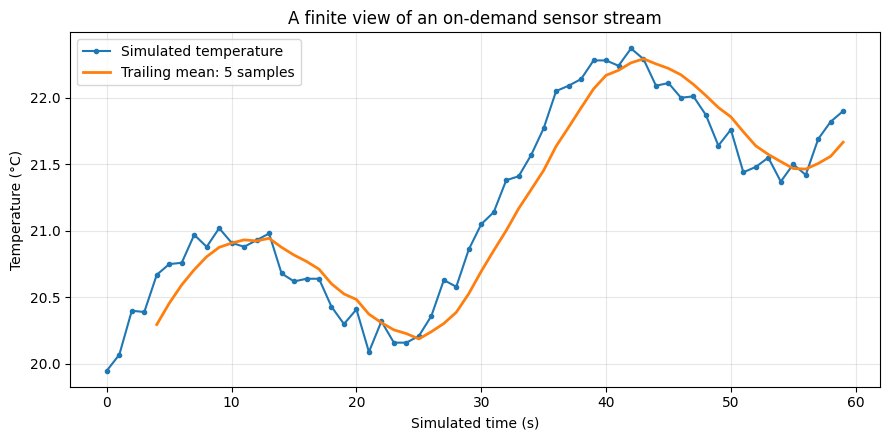

In [19]:
try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None
    print("Optional plots skipped: install matplotlib to enable them.")

plot_records = list(islice(simulated_sensor(seed=7), 60))
plot_times = [record["time_s"] for record in plot_records]
plot_values = [record["temp_c"] for record in plot_records]
window_size_for_plot = 5
reference_means = [
    sum(plot_values[end - window_size_for_plot + 1 : end + 1]) / window_size_for_plot
    for end in range(window_size_for_plot - 1, len(plot_values))
]

if plt is not None:
    plt.figure(figsize=(9, 4.5))
    plt.plot(plot_times, plot_values, marker=".", label="Simulated temperature")
    plt.plot(
        plot_times[window_size_for_plot - 1 :],
        reference_means,
        linewidth=2,
        label=f"Trailing mean: {window_size_for_plot} samples",
    )
    plt.xlabel("Simulated time (s)")
    plt.ylabel("Temperature (°C)")
    plt.title("A finite view of an on-demand sensor stream")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

<a id="s10"></a>

# 10. A small iterator toolbox, batches, and `yield from`

> **New requirement:** “Some sensors send packets containing several measurements. We need
> to combine streams and sometimes package their results into new batches.”

The standard-library `itertools` module provides iterator building blocks. Its results
are generally iterators, but not necessarily Python generator objects created with
`yield`. They share the iteration interface, which is why we can connect them to our
own generator functions.

| Tool | Useful question |
|:--|:--|
| `islice(source, n)` | Can I consume at most `n` items from this position? |
| `count(start, step)` | Can I generate consecutive labels without a prepared list? |
| `chain(a, b)` | Can I traverse `a`, then `b`? |
| `pairwise(source)` | Can I compare each item with its immediate predecessor? |
| `takewhile(rule, source)` | Can I take the initial run for which a rule holds? |
| `tee(source, 2)` | Can I create two traversal branches, accepting possible buffering? |

Reference: [itertools](https://docs.python.org/3.13/library/itertools.html).

In [20]:
from itertools import chain, count, pairwise, takewhile, tee

print("Five sample labels:", list(islice(count(100), 5)))
print("Two sessions:", list(chain([20, 21], [22, 23])))
print("Neighbouring pairs:", list(pairwise([20.0, 20.4, 21.0])))
print("Changes:", [new - old for old, new in pairwise([20.0, 20.4, 21.0])])

source = iter([20.0, 21.0, 25.0, 22.0])
print("Initial cool period:", list(takewhile(lambda value: value < 23.0, source)))
print("Next source item after takewhile:", next(source))

Five sample labels: [100, 101, 102, 103, 104]
Two sessions: [20, 21, 22, 23]
Neighbouring pairs: [(20.0, 20.4), (20.4, 21.0)]
Changes: [0.3999999999999986, 0.6000000000000014]
Initial cool period: [20.0, 21.0]
Next source item after takewhile: 22.0


The 25.0 reading is absent from the last output because `takewhile` had to consume it to
discover that the condition failed. It stops rather than searching for later matches.
That differs from a filter, which would continue looking and could still yield 22.0.

`chain` also has an order-sensitive meaning: it exhausts the first input before advancing
the second. Chaining an endless first sensor with a second sensor would never reach the
second. Combining simultaneous live devices fairly is a different requirement.

### Two consumers are not automatically two copies

A logger and dashboard cannot safely assume that two names for one iterator will each
receive every measurement. `tee` supplies separate traversal positions by retaining
items that a slower branch still needs. A branch that falls far behind can therefore
make the buffer grow. It is not free duplication, and it does not deep-copy the records.
After splitting, advance the returned branches rather than the original source.

In [22]:
fast, slow = tee(iter([20.0, 21.0, 22.0]), 2)
print("Fast branch:", next(fast), next(fast))
print("Slow branch still receives:", next(slow))
print("Fast remainder:", list(fast))
print("Slow remainder:", list(slow))

Fast branch: 20.0 21.0
Slow branch still receives: 20.0
Fast remainder: [22.0]
Slow remainder: [21.0, 22.0]


### Turn a stream into small batches

A batch boundary is another kind of state. With a batch size of three, we collect three
items, yield that group, then start a new group. The final group may be shorter if the
input ends. We never need to retain earlier groups inside the batching generator.

Our batches will be tuples. Each yielded tuple is a stable snapshot of that group's
references. The tuple does not deep-copy mutable elements, but clearing a later working
list will not erase the tuple's entries. This makes the batch boundary easier to reason
about than repeatedly yielding and clearing the same list object.

<a id="e09"></a>

## E09: Package readings into finite batches

Write `batches(values, batch_size)` to yield tuples of up to `batch_size` items. Preserve order, include a final incomplete batch, and produce no empty batch. For `range(7)` and size 3, yield `(0, 1, 2)`, `(3, 4, 5)`, and `(6,)`.

Keep at most one working batch, not the whole input. Use the same size-validation policy as E08: `TypeError` for non-integer or boolean sizes, `ValueError` for zero or negative sizes. Validation may occur on first iteration. Asking for the first batch must not consume any item belonging to the second batch.

**Hint.** Append into a small list, yield a tuple when it reaches the target size, then start a new list.
After the loop, yield the working group only when it is non-empty.

In [23]:
def batches(values, batch_size):
    # TODO: yield independent tuple batches, including a final partial batch.
    raise NotImplementedError

In [25]:
def check_ex9():
    assert list(batches(range(7), 3)) == [(0, 1, 2), (3, 4, 5), (6,)]
    assert list(batches(range(6), 3)) == [(0, 1, 2), (3, 4, 5)]
    assert list(batches([], 3)) == []
    assert list(batches([20, 21], 1)) == [(20,), (21,)]
    assert_raises(ValueError, lambda: list(batches([1], 0)))
    assert_raises(ValueError, lambda: list(batches([1], -1)))
    assert_raises(TypeError, lambda: list(batches([1], 1.5)))
    assert_raises(TypeError, lambda: list(batches([1], True)))
    seen = []

    def source():
        for value in range(7):
            seen.append(value)
            yield value

    stream = batches(source(), 3)
    assert isinstance(stream, GeneratorType)
    assert seen == []
    first = next(stream)
    assert first == (0, 1, 2)
    assert seen == [0, 1, 2]
    second = next(stream)
    assert first == (0, 1, 2)
    assert second == (3, 4, 5)
    assert seen == list(range(6))
    stream.close()


run_check("Ex9", check_ex9)

Ex9: TODO — replace the placeholder, then rerun this check.


### `yield` one object, or `yield from` its items?

Suppose a device sends `[20.0, 21.0]` as one packet. `yield packet` offers the entire packet as **one** output object. `yield from packet` delegates iteration to the packet and offers its elements separately. The distinction is visible in the next cell.

For simple value iteration, `yield from part` behaves like a loop that yields each item in `part`. Full delegation also forwards generator control operations and can capture a subgenerator's return value; those advanced aspects appear in the optional section.

Reference: [PEP 380: delegating to a subgenerator](https://peps.python.org/pep-0380/).

In [27]:
def packet_as_one_item():
    yield [20.0, 21.0]


def packet_as_separate_items():
    yield from [20.0, 21.0]


print("yield packet:", list(packet_as_one_item()))
print("yield from packet:", list(packet_as_separate_items()))

yield packet: [[20.0, 21.0]]
yield from packet: [20.0, 21.0]


<a id="e10"></a>

## E10: Flatten one level of received batches

Write `flatten_batches(received_batches)` using `yield from`. Each batch is an iterable of numbers; the outer input may itself be an iterator. Yield the numbers in batch order, skipping empty batches naturally. Flatten **one level only**, without building one large combined list or recursively inspecting the items.

**Hint.** Use one outer loop over the batches and delegate each batch's iteration with `yield from`.

In [28]:
def flatten_batches(received_batches):
    # TODO: yield each number from each batch, preserving order.
    raise NotImplementedError

In [29]:
def check_ex10():
    assert list(flatten_batches([[20, 21], [], [22]])) == [20, 21, 22]
    assert list(flatten_batches([])) == []
    assert list(flatten_batches([[], []])) == []
    assert list(flatten_batches([iter([20, 21]), iter([22])])) == [20, 21, 22]
    seen = []

    def source():
        for batch in [[20, 21], [22]]:
            seen.append(batch)
            yield batch

    stream = flatten_batches(source())
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == 20
    assert seen == [[20, 21]]
    assert next(stream) == 21
    assert seen == [[20, 21]]
    assert next(stream) == 22
    assert seen == [[20, 21], [22]]
    stream.close()


run_check("Ex10", check_ex10)

Ex10: TODO — replace the placeholder, then rerun this check.


<a id="s11"></a>

# 11. Read files lazily and decide how to handle bad data

> **New requirement:** “Replay yesterday's sensor log, and explain malformed measurements.”

A file object can be iterated line by line. That lets a processing loop begin without
loading the complete file into a list. It does not mean disk access is literally one
byte or one physical read per request; the I/O system may buffer data internally.

We first create a tiny CSV file inside a temporary directory so the example is completely
self-contained. `csv.DictReader` gives us one row dictionary at a time. CSV fields are
strings here, so we convert the sample and temperature deliberately. Our demonstration
CSV has a known header and valid rows; error policy is the next step.

Reference: [Python CSV reading](https://docs.python.org/3.13/library/csv.html).

In [30]:
import csv
from pathlib import Path
from tempfile import TemporaryDirectory


def read_csv_records(path):
    with Path(path).open("r", encoding="utf-8", newline="") as file:
        for row in csv.DictReader(file):
            yield {"sample": int(row["sample"]), "temp_c": float(row["temp_c"])}


with TemporaryDirectory() as directory:
    path = Path(directory) / "readings.csv"
    path.write_text("sample,temp_c\n0,20.0\n1,21.5\n2,23.0\n", encoding="utf-8")
    for record in read_csv_records(path):
        print(record)
# The generated example file is removed with its temporary directory.

{'sample': 0, 'temp_c': 20.0}
{'sample': 1, 'temp_c': 21.5}
{'sample': 2, 'temp_c': 23.0}


### Where does an error happen?

A parsing error inside a generator usually occurs during consumption, not when the
generator object is created. In the strict parser below, the first line is accepted and
the next line fails. The `try` must surround the operation that actually advances the
stream if it is to catch that failure.

If an exception escapes a generator body, catching it outside does not make that same
generator resume at its next line. Its execution has ended. Recovering from bad records
requires handling those expected failures **inside** the record-processing loop, or
constructing a different recovery policy around the source.

In [31]:
def strict_temperatures(lines):
    for line in lines:
        yield float(line.strip())


raw_lines = iter(["20.0", "sensor offline", "23.0"])
strict = strict_temperatures(raw_lines)
print("Object created successfully")
print("First parsed value:", next(strict))
try:
    print(next(strict))
except ValueError as error:
    print("Expected parsing failure:", type(error).__name__)
print("The failed generator is finished:", next(strict, "END"))
print("The original source still has:", next(raw_lines))

Object created successfully
First parsed value: 20.0
Expected parsing failure: ValueError
The failed generator is finished: END
The original source still has: 23.0


For our dashboard, silently ignoring bad measurements would make diagnosis difficult.
We will instead produce **events**: an accepted temperature or a structured rejection.
This lets a downstream consumer count failures or show an audit message without mixing
printing into the parser. Blank lines and full-line comments are not measurements and
will produce no event.

The exercise uses a simpler one-value-per-line format rather than CSV, so we can focus
on the generator and error policy. It also rejects `NaN` and infinity: those strings
can be converted by `float`, but they are not finite numerical measurements under our
contract. Catching only conversion exceptions is not sufficient validation.

Keep exception handlers narrow. Catch the conversion failure you expect, rather than
wrapping the entire pipeline in `except Exception: pass`, which could hide programming
errors as though they were merely bad sensor data.

<a id="e11"></a>

## E11: Keep valid values and explain rejected lines

Write `parse_events(lines)` for an iterable of strings, one potential Celsius reading per line. Number all input lines starting at 1. Strip surrounding whitespace. Skip blank lines and lines whose stripped text starts with `#`.

For a finite parsed float, yield exactly
`{"status": "ok", "line_number": number, "temp_c": value}`.
For a failed `float` conversion, yield exactly
`{"status": "error", "line_number": number, "text": text, "reason": "not a number"}`.
For a parsed non-finite value, use the same error shape with reason `"not finite"`. Continue after rejected lines. Do not print or store every event in a list.

**Hint.** Use `enumerate(lines, start=1)`. Catch `ValueError` around `float(text)`, then check
`isfinite` separately for successful conversions.

In [32]:
def parse_events(lines):
    # TODO: yield accepted or rejected events, continuing after bad measurements.
    raise NotImplementedError

In [34]:
def check_ex11():
    lines = [" 20.5 ", "", " # calibration note", "offline", "NaN", "inf", "-2"]
    assert list(parse_events(lines)) == [
        {"status": "ok", "line_number": 1, "temp_c": 20.5},
        {
            "status": "error",
            "line_number": 4,
            "text": "offline",
            "reason": "not a number",
        },
        {"status": "error", "line_number": 5, "text": "NaN", "reason": "not finite"},
        {"status": "error", "line_number": 6, "text": "inf", "reason": "not finite"},
        {"status": "ok", "line_number": 7, "temp_c": -2.0},
    ]
    assert list(parse_events([])) == []
    assert list(parse_events(["", " # note "])) == []
    assert list(parse_events(["1e999"]))[0]["reason"] == "not finite"
    seen = []

    def source():
        for line in ["", "20.5", "offline", "22"]:
            seen.append(line)
            yield line

    stream = parse_events(source())
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == {"status": "ok", "line_number": 2, "temp_c": 20.5}
    assert seen == ["", "20.5"]
    remaining = list(stream)
    assert remaining[-1] == {"status": "ok", "line_number": 4, "temp_c": 22.0}


run_check("Ex11", check_ex11)

Ex11: TODO — replace the placeholder, then rerun this check.


### Immediate configuration checks versus delayed data checks

Sometimes a bad setting should fail immediately, before any stream is consumed. An
ordinary function can validate the setting and return a generator expression or an inner
generator. This creates a clear boundary: configuration is checked at construction;
measurement processing still happens during iteration.

The next example intentionally rejects an infinite calibration offset. It is not a
complete validation framework; numerical settings are assumed except for finiteness.

In [35]:
def make_calibrated_values(values, offset_c):
    if not isfinite(offset_c):
        raise ValueError("offset_c must be finite")
    return (value + offset_c for value in values)


try:
    invalid = make_calibrated_values([20.0], float("inf"))
except ValueError as error:
    print("Rejected at construction:", error)
print("Valid configuration:", list(make_calibrated_values([20.0, 21.0], 0.3)))

Rejected at construction: offset_c must be finite
Valid configuration: [20.3, 21.3]


<a id="s12"></a>

# 12. Resource lifetime: who closes the file?

> **New requirement:** “The user may close the dashboard before the file is exhausted.”

A suspended generator can retain more than numerical state. It can keep a file open
while it waits for the caller's next request. We therefore need an explicit owner for
that resource, especially when iteration ends early.

A `break` leaves a loop; it does not by itself call `close` on the iterator. A generator's
`finally` block runs when execution leaves its protected region, including normal
completion and explicit closure after it has started. Do not rely on the timing of
garbage collection to release an important file or connection.

References: [generator finalization](https://docs.python.org/3.13/reference/expressions.html#generator-iterator-methods)
and [contextlib.closing](https://docs.python.org/3.13/library/contextlib.html#contextlib.closing).

In [36]:
def traced_session():
    print("Session starts")
    try:
        yield 20.0
        yield 21.0
    finally:
        print("Session cleanup runs")


session = traced_session()
for value in session:
    print("Consumer received:", value)
    break
print("We left the loop, but still retain the paused session")
session.close()
print("Now the session is closed")

Session starts
Consumer received: 20.0
We left the loop, but still retain the paused session
Session cleanup runs
Now the session is closed


### The too-early closing mistake

The next function opens a file and returns a generator expression referring to that file.
But the ordinary function immediately leaves its `with` block, which closes the file
**before** the returned expression is consumed. Laziness has moved the reading past the
lifetime of the resource it needs.

In [37]:
def wrong_file_reader(path):
    with Path(path).open("r", encoding="utf-8") as file:
        return (line.strip() for line in file)


with TemporaryDirectory() as directory:
    path = Path(directory) / "small_log.txt"
    path.write_text("20.0\n21.0\n", encoding="utf-8")
    broken_reader = wrong_file_reader(path)
    try:
        next(broken_reader)
    except ValueError as error:
        print("Expected closed-file error:", error)

Expected closed-file error: I/O operation on closed file.


A straightforward solution is to let the **caller own the file** and finish using the
pipeline inside the caller's `with` block. Then even an early `break` still leaves that
block and closes the file. This is often the clearest arrangement when several stages
are connected.

In [38]:
with TemporaryDirectory() as directory:
    path = Path(directory) / "small_log.txt"
    path.write_text("20.0\n21.0\n22.0\n", encoding="utf-8")
    with path.open("r", encoding="utf-8") as file:
        values = (float(line) for line in file)
        for value in islice(values, 1):
            print("Only display one:", value)
        values.close()
    print("Caller-owned file closed:", file.closed)

Only display one: 20.0
Caller-owned file closed: True


Another valid arrangement is a generator that owns its file internally. It must then be
closed when a consumer stops early. `contextlib.closing` calls an object's `close` method
when the surrounding block ends, including when an exception occurs.

Simply closing the last generator of an arbitrary multi-stage pipeline is not a general
promise to close every upstream iterator. Ownership should be explicit. Manage the
resource-owning source in a `with` block, rather than hoping all wrappers propagate
cleanup. `yield from` has special delegation rules, but a plain `for` wrapper does not
inherit those rules automatically.

In [39]:
from contextlib import closing


def owned_file_lines(path):
    with Path(path).open("r", encoding="utf-8") as file:
        for line in file:
            yield line.strip()


with TemporaryDirectory() as directory:
    path = Path(directory) / "small_log.txt"
    path.write_text("20.0\n21.0\n22.0\n", encoding="utf-8")
    with closing(owned_file_lines(path)) as lines:
        print("First line:", next(lines))
    print("Reader explicitly closed:", next(lines, "END"))

First line: 20.0
Reader explicitly closed: END


<a id="e12"></a>

## E12: Make cleanup observable and reliable

Write `managed_readings(values, events)` as a generator. On first execution of its body, append `"started"` to the supplied `events` list. Yield the input values unchanged. Append `"closed"` exactly once in a `finally` block when the started generator ends or is explicitly closed.

The list is deliberate instrumentation, not a pure calculation. Creating the generator must not change it. Closing a generator that has **never been started** should leave it empty, because its body never entered the protected region. Do not catch and hide arbitrary source exceptions. This exercise logs the wrapper's lifetime; it does not claim ownership of an arbitrary upstream iterable.

**Hint.** Append the start event before entering `try`; put the yielding loop inside `try` and the
cleanup event inside `finally`.

In [40]:
def managed_readings(values, events):
    # TODO: log the beginning and guaranteed end of a started generator.
    raise NotImplementedError

In [41]:
def check_ex12():
    from contextlib import closing

    events = []
    stream = managed_readings([20, 21], events)
    assert isinstance(stream, GeneratorType)
    assert events == []
    assert next(stream) == 20
    assert events == ["started"]
    stream.close()
    assert events == ["started", "closed"]
    stream.close()
    assert events == ["started", "closed"]
    events = []
    assert list(managed_readings([], events)) == []
    assert events == ["started", "closed"]
    events = []
    assert list(managed_readings([20, 21], events)) == [20, 21]
    assert events == ["started", "closed"]
    events = []
    unopened = managed_readings([20], events)
    unopened.close()
    assert events == []
    events = []
    with closing(managed_readings([20, 21], events)) as stream:
        assert next(stream) == 20
    assert events == ["started", "closed"]
    events = []

    def failing_source():
        yield 20
        raise ValueError("device failure")

    stream = managed_readings(failing_source(), events)
    assert next(stream) == 20
    assert_raises(ValueError, next, stream)
    assert events == ["started", "closed"]


run_check("Ex12", check_ex12)

Ex12: TODO — replace the placeholder, then rerun this check.


<a id="s13"></a>

# 13. What generators save — and what they do not

> **New requirement:** “Explain the memory benefit honestly, using a reproducible experiment.”

We should measure the work we actually care about. Creating a generator object and
stopping there is not a fair comparison with building a completed list. The generator
has not produced its results yet. Our experiment therefore computes the **same final
sum** both ways, including full consumption in each measurement.

The list version stores all squared sample labels before summing them. The generator
version offers squared labels as the sum requests them. Neither input is a prebuilt
large list: both start from `range(n)`. This isolates the intermediate-output choice.

`tracemalloc` reports allocations it tracks during the measured interval, including a
peak. It is not the total resident memory of the Python process, and it does not account
for every possible allocation made by native libraries. We compare these pure-Python
examples without claiming universal memory ratios or speed improvements.

Reference: [tracemalloc measurements](https://docs.python.org/3.13/library/tracemalloc.html).

In [44]:
import tracemalloc


def total_with_list(n):
    return sum([sample * sample for sample in range(n)])


def total_with_generator(n):
    return sum(sample * sample for sample in range(n))


def measured_peak(function, n):
    if tracemalloc.is_tracing():
        raise RuntimeError(
            "Use a fresh kernel or stop your own tracing before this demo."
        )
    tracemalloc.start()
    try:
        result = function(n)
        _, peak_bytes = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return result, peak_bytes


sizes = [1_000, 10_000, 100_000]
list_peaks = []
generator_peaks = []
for n in sizes:
    list_total, list_peak = measured_peak(total_with_list, n)
    generator_total, generator_peak = measured_peak(total_with_generator, n)
    assert list_total == generator_total
    list_peaks.append(list_peak / 1024)
    generator_peaks.append(generator_peak / 1024)
    print(
        f"n={n:>7,}: list peak {list_peak / 1024:>9.1f} KiB; "
        f"generator peak {generator_peak / 1024:>7.1f} KiB; equal totals"
    )

n=  1,000: list peak      40.0 KiB; generator peak     0.5 KiB; equal totals
n= 10,000: list peak     395.5 KiB; generator peak     2.0 KiB; equal totals
n=100,000: list peak    3906.7 KiB; generator peak     3.1 KiB; equal totals


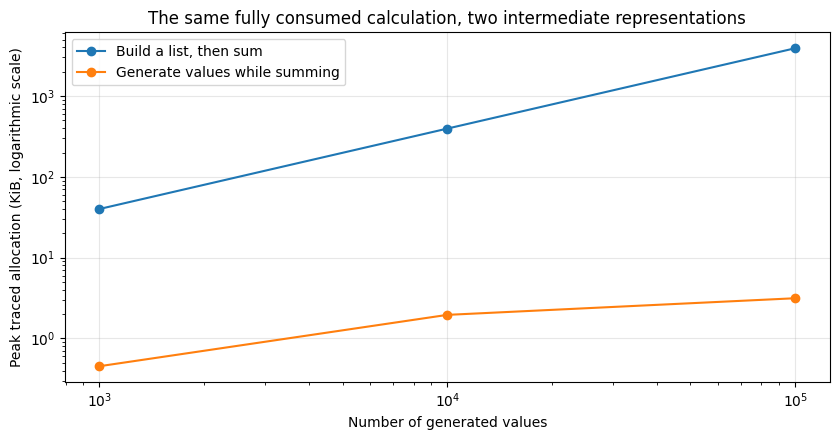

In [45]:
if plt is not None:
    plt.figure(figsize=(8.5, 4.5))
    plt.plot(sizes, list_peaks, marker="o", label="Build a list, then sum")
    plt.plot(sizes, generator_peaks, marker="o", label="Generate values while summing")
    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Number of generated values")
    plt.ylabel("Peak traced allocation (KiB, logarithmic scale)")
    plt.title("The same fully consumed calculation, two intermediate representations")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

Read the measurements produced in your own runtime, not a memorised ratio. The list
has to retain every intermediate square until summation. The generator calculation
retains a small set of active values and state, rather than the full sequence. Exact
byte counts can vary with the runtime and allocation details. A notebook kernel
can also make unrelated tracked allocations during that interval; very small peaks
are especially sensitive to this background noise.

This does **not** prove that generators are always faster. Both versions perform all
of the arithmetic here. Generator advancement has its own overhead; a list can be an
excellent choice for repeated access, and numerical array libraries serve other needs.
When only the first matching result is required, lazy processing may also avoid work,
but that is a different comparison from consuming every result.

### Look at the whole pipeline

A generator can still use a great deal of memory if it creates a large internal list,
retains a large input object, buffers history, or feeds a consumer that stores everything.
`list(stream)` and `sorted(stream)` materialise their results. A bounded window stores
its window; lagging `tee` branches can retain a growing buffer. Merely seeing `yield`
in the code is not a memory guarantee.

Likewise, `sys.getsizeof(generator)` alone is not a measurement of the full computation
or every object the generator keeps reachable. The useful question is: **which objects
must remain available at each point, and why?**

A final summary can often be calculated in one pass without keeping every reading.
That function will be a **consumer**, not necessarily another generator. The next
exercise makes this distinction explicit.

<a id="e13"></a>

## E13: Summarise a one-pass stream

Write the ordinary function `stream_summary(values)`. Consume a **finite** iterable of finite numbers once and return exactly `{"count": count, "mean_c": mean, "max_c": maximum}`.
For an empty input, use count 0 and `None` for the mean and maximum.

Keep only a count, total, and current maximum. Do not call `list`, `tuple`, `sorted`, or
`len` on the input. This function should return a final dictionary, not yield intermediate
results. It is not suitable for an unbounded input without an upstream limit.

**Hint.** Use `None` for the initial maximum; starting with zero would fail when every reading is negative.

In [46]:
def stream_summary(values):
    # TODO: return one summary after a single finite traversal.
    raise NotImplementedError

In [47]:
def check_ex13():
    assert stream_summary(iter([20, 22, 24])) == {
        "count": 3,
        "mean_c": 22.0,
        "max_c": 24,
    }
    assert stream_summary([]) == {"count": 0, "mean_c": None, "max_c": None}
    assert stream_summary(iter([-5, -3, -4])) == {
        "count": 3,
        "mean_c": -4.0,
        "max_c": -3,
    }
    assert stream_summary([7]) == {"count": 1, "mean_c": 7.0, "max_c": 7}
    source = iter([20, 22])
    result = stream_summary(source)
    assert isinstance(result, dict)
    assert next(source, "END") == "END"
    assert result == {"count": 2, "mean_c": 21.0, "max_c": 22}


run_check("Ex13", check_ex13)

Ex13: TODO — replace the placeholder, then rerun this check.


<a id="s14"></a>

# 14. Capstone: a small streaming dashboard

> **New requirement:** “Use the average of the most recent measurements to describe
> whether the room is warm. Keep the code small enough to inspect.”

We now have enough pieces for a useful monitoring calculation. The source might be our
simulator, a replayed file, or a prepared list used in a test. The monitor should not
need to know which one it receives. Its input contract describes records, not a
particular source implementation.

Our capstone has three responsibilities: retain a bounded window, calculate its mean,
and attach a boolean alert status. File access, simulation, printing, and plotting stay
outside. An alert here is **information about a window**, not a command to control a
heater or send an email.

```text
source records → optional calibration → bounded-window monitor → display or collect
                        no filtering of cool values before averaging
```

Do not filter out cool readings before computing the mean. That would answer a different
question: the mean of selected warm measurements, not the mean of the recent room
measurements. Similarly, do not replace a missing or invalid sample by an invented zero.
An upstream validation policy must decide how invalid records are handled.

### Work one example by hand

Use the temperatures 20, 21, 25, 26, 20, 20, a window size of three, and an alert threshold
of 23 °C. Associate an output with the sample number of the **last** value in its window.

| Last sample | Current full window | Mean | Alert at or above 23 °C? |
|:--|:--|:--|:--|
| 2 | 20, 21, 25 | 22 | False |
| 3 | 21, 25, 26 | 24 | True |
| 4 | 25, 26, 20 | 71 / 3 | True |
| 5 | 26, 20, 20 | 22 | False |

The first result requires three source measurements. Each later result needs one new
measurement. This is a sample-count window, not a time-duration window: with irregular
sampling, “three readings” does not mean “three seconds”.

<a id="e14"></a>

## E14: Build the monitoring generator

Write `monitor(records, window_size=3, threshold_c=23.0)`. Each input record contains `sample` and `temp_c`; samples arrive in order and temperatures are finite. They have already been validated and, when necessary, calibrated.

For every **complete** trailing window, yield a new dictionary with exactly:
`{"sample": last_sample, "mean_c": current_mean, "alert": current_mean >= threshold_c}`. Yield both alerting and non-alerting windows. Use the sample identifier from the current record; do not invent a new numbering scheme. Retain only the current window and do not change source records.

Use E08's size-validation policy. Thresholds are assumed finite numerical values. The function must accept a one-pass source and must not read ahead beyond the records needed for the current output. It may use a bounded deque directly and does **not** need any earlier unfinished exercise function.

**Hint.** Retain recent temperatures in a deque, but use the current record's sample number for
the output. Keep the threshold test after calculating the complete window mean.

In [48]:
def monitor(records, window_size=3, threshold_c=23.0):
    # TODO: yield one dashboard record for each complete recent window.
    raise NotImplementedError

In [49]:
def check_ex14():
    records = [
        {"sample": i, "temp_c": value}
        for i, value in enumerate([20, 21, 25, 26, 20, 20])
    ]
    snapshot = [record.copy() for record in records]
    output = list(monitor(iter(records), 3, 23.0))
    assert [row["sample"] for row in output] == [2, 3, 4, 5]
    assert [row["alert"] for row in output] == [False, True, True, False]
    assert all(
        isclose(row["mean_c"], expected)
        for row, expected in zip(output, [22, 24, 71 / 3, 22])
    )
    assert all(set(row) == {"sample", "mean_c", "alert"} for row in output)
    assert len({id(row) for row in output}) == len(output)
    assert records == snapshot
    assert list(monitor([], 3)) == []
    assert list(monitor(records[:2], 3)) == []
    assert list(monitor([{"sample": 99, "temp_c": 23.0}], 1, 23.0)) == [
        {"sample": 99, "mean_c": 23.0, "alert": True}
    ]
    assert_raises(ValueError, lambda: list(monitor(records, 0)))
    assert_raises(TypeError, lambda: list(monitor(records, 1.5)))
    assert_raises(TypeError, lambda: list(monitor(records, True)))
    seen = []

    def source():
        for record in records:
            seen.append(record["sample"])
            yield record

    stream = monitor(source(), 3, 23.0)
    assert isinstance(stream, GeneratorType)
    assert seen == []
    assert next(stream) == {"sample": 2, "mean_c": 22.0, "alert": False}
    assert seen == [0, 1, 2]
    assert next(stream) == {"sample": 3, "mean_c": 24.0, "alert": True}
    assert seen == [0, 1, 2, 3]
    stream.close()


run_check("Ex14", check_ex14)

Ex14: TODO — replace the placeholder, then rerun this check.


### Run your monitor on the simulator

This cell uses only the guided examples plus your E14 implementation. It does not depend
on solutions to earlier exercises. Until E14 is completed, it reports TODO and leaves
the rest of the notebook runnable.

We limit **input** to twelve simulated readings, then apply a known calibration, then
calculate the monitoring reports. All full windows are printed, including those with
no alert. It is worth inspecting the first and last sample identifiers rather than
looking only at the mean values.

In [50]:
with closing(simulated_sensor(seed=7)) as source:
    calibrated = add_calibration(islice(source, 12), offset_c=0.3)
    try:
        dashboard_rows = list(monitor(calibrated, window_size=3, threshold_c=21.0))
    except NotImplementedError:
        print("E14 demo: TODO — complete monitor, then rerun this cell.")
    else:
        for row in dashboard_rows:
            print(
                f"sample={row['sample']:2d}, mean={row['mean_c']:.2f} °C, alert={row['alert']}"
            )
    finally:
        calibrated.close()

E14 demo: TODO — complete monitor, then rerun this cell.


**Design discussion, not another required exercise:** where would you put an audit log of
invalid records? What would change if “recent” meant the last ten seconds rather than
the last ten samples? How would you ensure a slow display does not lose measurements
from hardware that produces data independently of this pull-based Python pipeline?

The generator abstraction helps organise traversal. It does not, by itself, answer
questions about physical acquisition timing, persistence, buffering capacity, or failure
recovery. Those requirements need to be made explicit in the surrounding system.

<a id="s15"></a>

# 15. Optional: send information back into a generator

> **Optional requirement:** “Adjust the simulation while it is paused, without recreating it.”

Everything so far uses generators as sources of values. A generator can also receive
a value at its suspension point. In `message = yield output`, the `output` travels to
the caller now; the assignment to `message` happens when the caller later resumes the
generator. `generator.send(value)` supplies that incoming value and runs until the
next yielded result or termination.

A generator must first reach a suspension point before it can receive a non-`None`
value. Start it with `next(generator)` or `generator.send(None)`. For an already-started
generator, `next(generator)` resumes it as a `send(None)` would.

Reference: [PEP 342 — enhanced generators](https://peps.python.org/pep-0342/).

In [52]:
def command_channel():
    command = yield "ready for a command"
    yield f"received command: {command}"


channel = command_channel()
print("Prime:", next(channel))
print("Send and receive:", channel.send("increase calibration by 0.3 °C"))
channel.close()

Prime: ready for a command
Send and receive: received command: increase calibration by 0.3 °C


The single `yield` expression participates in two different moments. First it sends
“ready for a command” out. Later, `.send(...)` makes that suspended expression evaluate
to the incoming command, so the assignment completes. The function then reaches its
next `yield`, and that new output is the return value of `.send(...)`.

This is a useful mechanism to understand, but ordinary source-transform-consumer
pipelines rarely need it. Do not introduce two-way communication unless it makes the
requirement clearer. It creates a protocol: both sides must agree about when values
are expected and what those values mean.

In particular, `send` does not schedule background work. Generator-based communication
is not automatically the same thing as modern `async`/`await` programming. Asynchronous
generators and `async for` address another interface, especially relevant when waiting
for I/O; they are outside this notebook's main path.

<a id="e15"></a>

## E15: Adjust a ramp while it is running, optional

Write `adjustable_ramp(start_c=20.0, default_step_c=0.5)` as an unbounded generator ofnumerical temperatures. Its first yielded value is `start_c`. At each later resumption, receive a step through `send`. Add that step before yielding the next temperature. If the incoming step is `None`, use `default_step_c` instead.

Assume finite numerical settings and non-`None` commands. A zero step means hold the current value; a negative step means decrease it. For example: `next(g)` gives 20.0, `g.send(2.0)` gives 22.0, and `next(g)` then gives 22.5. Close the generator when done.

**Hint.** The assignment `step_c = yield current_c` spans the pause. Test `step_c is None`, not
`if not step_c`, so that a legitimate zero adjustment is preserved.

In [54]:
def adjustable_ramp(start_c=20.0, default_step_c=0.5):
    # TODO: receive a step at each pause and yield the updated value.
    raise NotImplementedError

In [55]:
def check_ex15():
    stream = adjustable_ramp(20.0, 0.5)
    assert isinstance(stream, GeneratorType)
    assert next(stream) == 20.0
    assert stream.send(2.0) == 22.0
    assert next(stream) == 22.5
    assert stream.send(0.0) == 22.5
    assert stream.send(-1.0) == 21.5
    stream.close()
    assert next(stream, "END") == "END"
    stream = adjustable_ramp(10.0, 1.0)
    assert stream.send(None) == 10.0
    assert stream.send(None) == 11.0
    stream.close()
    stream = adjustable_ramp()
    assert_raises(TypeError, stream.send, 1.0)
    stream.close()


run_check("Ex15", check_ex15)

Ex15: TODO — replace the placeholder, then rerun this check.


### A generator can finish with a return value

`return value` ends a generator, but the value is not an extra ordinary item seen by `for` or `list`. It is attached to the `StopIteration` signalling completion. Another generator can receive that value through `result = yield from child`.

This separates the stream of yielded readings from a final summary of the subtask. It is an advanced delegation feature, not a replacement for an ordinary consumer function when a final report is all we need.

Reference: [PEP 380 return values during delegation](https://peps.python.org/pep-0380/).

In [57]:
def readings_with_count(values):
    count_seen = 0
    for value in values:
        count_seen += 1
        yield value
    return count_seen


def delegated_session(values):
    count_seen = yield from readings_with_count(values)
    yield {"session_count": count_seen}


print("Ordinary yielded items:", list(readings_with_count([20.0, 21.0])))
print(
    "Outer generator deliberately adds a report:", list(delegated_session([20.0, 21.0]))
)

manual = readings_with_count([20.0])
print("One reading:", next(manual))
try:
    next(manual)
except StopIteration as finished:
    print("Separate return value:", finished.value)

Ordinary yielded items: [20.0, 21.0]
Outer generator deliberately adds a report: [20.0, 21.0, {'session_count': 2}]
One reading: 20.0
Separate return value: 1


The mixed numerical-and-dictionary stream in `delegateed_session` is intentional for
this demonstration. A production data contract would need to document that mixture,
or use a consistent event shape. The final dictionary is visible only because the
**outer** generator explicitly yields it; the child's `return` did not automatically add it to ordinary iteration.

For completeness, `.throw(exception)` injects an exception at a generator's current suspension point, while `.close()` requests termination. These methods are rarely needed for our monitoring pipeline. Cleanup should finish rather than trying to yield a new
measurement during closure. Their detailed protocol is documented in the
[generator-method reference](https://docs.python.org/3.13/reference/expressions.html#generator-iterator-methods).

<a id="s16"></a>

# 16. Choose the simplest design that meets the requirement

Generators are useful because they let ordinary-looking code participate in incremental
processing. They do not make lists obsolete, remove all state, or solve all acquisition
problems. Ask what the caller needs, what must remain in memory, and what should happen
if consumption stops early.

| Need | A reasonable starting point |
|:--|:--|
| A small collection to inspect repeatedly or access by position | A list or tuple. |
| A simple lazy transformation or selection | A generator expression. |
| A multi-step stream with branches or small local state | A generator function. |
| A standard slicing, combining, or neighbouring-pair operation | An appropriate iterator tool. |
| One final statistic from a finite source | An ordinary one-pass consumer. |
| Repeated replay of recorded data | A reusable collection, reopened file, or source factory. |
| Independent hardware acquisition, timeouts, or slow consumers | Explicit acquisition and buffering design, possibly alongside generators. |

### Common mistakes to recognise

| Symptom | Likely explanation or next question |
|:--|:--|
| A second loop produces nothing | Did the first loop exhaust the same iterator? |
| Creating a generator prints nothing | Its body may not have started; who requests the first item? |
| `next(stream)` takes unexpectedly long | Is a filter searching, a window filling, or an I/O operation blocking? |
| `list(stream)` never finishes | Is the source unbounded, or is some stage waiting indefinitely? |
| Old saved records all change together | Are you yielding the same mutable object repeatedly? |
| A file is already closed when iteration starts | Did an ordinary function return lazy work from inside a finished `with` block? |
| Cleanup is missing after `break` | Who explicitly owns and closes the resource? |
| Memory still grows despite `yield` | Which input, buffer, internal list, or downstream collector is retaining data? |
| The generator cannot continue after an error | Did the exception escape and terminate its body? |
| The moving average looks too high | Were cool readings filtered out before averaging? |

### A compact glossary

**Iterable:** something that can supply an iterator. A list, a generator object, and a
file object can all be used in a `for` loop, but they do not have identical storage or
replay behaviour.

**Iterator:** one traversal with a current position, advanced through `next` and ended
through `StopIteration`.

**Generator function:** a function with `yield` in its own body. Calling it creates a
generator object rather than executing the body to completion.

**Generator object:** the iterator representing one created generator computation,
including its suspended execution state.

**Lazy evaluation:** postponing work until its result is requested. It is not a promise
that all input and configuration expressions are delayed, or that each request is fast.

**Consumer:** code that requests values from an iterator, such as a `for` loop, `sum`,
`list`, or another processing stage.

**Pipeline:** connected processing stages, where the output iterator of one stage can
serve as the input iterable of another.

**Exhaustion:** the end of a traversal. It is different from a generator being temporarily
paused at a `yield`.

**Materialisation:** collecting a stream's values into a concrete collection, such as a
list. It can be useful when intentional and bounded.

**Running calculation:** a result updated using all inputs seen so far, often with a
small summary state.

**Rolling window:** a bounded recent portion of the input, used to intentionally forget
older values.

**Data contract:** the agreed input and output shapes, meanings, ordering, validation,
and stopping behaviour of a component.

### Questions for a final discussion

Explain why a generator may save memory without saving arithmetic. Describe why an
output limit and an input limit can lead to different amounts of work. Then identify
the resource owner in a file-reading pipeline and explain what happens when a user
stops after the first report.

A strong explanation should connect the visible output to the requests that produced
it. “It uses `yield`” is a syntax observation; “it does not request a later record until
this report is consumed” is a behavioural claim that we can test.

In [58]:
print("Exercise status in this kernel:")
for label, status in exercise_status.items():
    print(f"  {label}: {status}")
print("\nUse the companion solutions notebook for worked answers and discussion.")

Exercise status in this kernel:
  Ex5: TODO
  Ex6: TODO
  Ex7: TODO
  Ex8: TODO
  E09: TODO
  Ex9: TODO
  Ex10: TODO
  E11: TODO
  Ex11: TODO
  Ex12: TODO
  Ex13: TODO
  Ex14: TODO
  Ex15: TODO

Use the companion solutions notebook for worked answers and discussion.


### Final remarks and the literature

The smart-home narrative, datasets, exercise requirements, code, and numerical examples are my idea and the teaching material follows it. I welcome any comments and remarks - especially regarding the text, which I updated recently.

The links below document the language and library behaviour used here. Python 3.13 documentation is used as a versioned reference; the executable examples use features available from Python 3.10 onwards. Historical PEPs explain design decisions, but their old syntax or restrictions may have been superseded.

Use the current versioned language reference for exact behaviour. Note, that this is a very active area that sees a lot of development.

| Topic | Primary reference |
|:--|:--|
| Iterables, iterators, and generators | [Python tutorial: iterators and generators](https://docs.python.org/3.13/tutorial/classes.html#iterators) |
| `iter`, `next`, and consumers | [Built-in functions](https://docs.python.org/3.13/library/functions.html) |
| Generator expressions and evaluation timing | [Python language reference](https://docs.python.org/3.13/reference/expressions.html#generator-expressions) |
| Generator expression design | [PEP 289](https://peps.python.org/pep-0289/) |
| Generator execution and methods | [Generator-iterator methods](https://docs.python.org/3.13/reference/expressions.html#generator-iterator-methods) |
| Why not raise `StopIteration` inside a generator? | [PEP 479](https://peps.python.org/pep-0479/) |
| Bounded slicing, chaining, pairs, and buffered branches | [itertools](https://docs.python.org/3.13/library/itertools.html) |
| Bounded recent history | [collections.deque](https://docs.python.org/3.13/library/collections.html#collections.deque) |
| Reading CSV records | [csv](https://docs.python.org/3.13/library/csv.html) |
| Explicit closure at scope exit | [contextlib.closing](https://docs.python.org/3.13/library/contextlib.html#contextlib.closing) |
| Measuring tracked allocations | [tracemalloc](https://docs.python.org/3.13/library/tracemalloc.html) |
| Two-way generator communication | [PEP 342](https://peps.python.org/pep-0342/) |
| Delegation and generator return values | [PEP 380](https://peps.python.org/pep-0380/) |
| Background on the original generator design | [PEP 255](https://peps.python.org/pep-0255/) |

